# 02 · Preprocessing

Notebook ini menjelaskan **apa yang dilakukan pada teks sebelum masuk model, dan mengapa**. Implementasinya di `src/preprocessing.py` (fungsi `preprocess`).

## 1. Mengapa perlu preprocessing?

Pesan customer di chat itu berantakan: singkatan (`sjd`, `brp`, `utk`), slang (`ga`, `gak`, `nggak`), typo (`pacrel`, `bordr`), emoji, angka dan nama yang berbeda di tiap pesan.
Model akan menganggap `sajadah` dan `sjd` sebagai dua kata yang tidak berhubungan, padahal artinya sama.

| Langkah | Contoh |
|---|---|
| Case folding, hapus emoji dan URL | `Halo 🙏` → `halo` |
| Masking | teks dalam tanda kutip → `NAMA`; `70x140` → `DIM`; `50rb`, `Rp200.000` → `UANG`; angka lain → `NUM` |
| Normalisasi slang/singkatan | `sjd` → `sajadah`, `brp` → `berapa`, `ga/gak/nggak` → `tidak`, `biji/buah` → `pcs` |
| Koreksi typo terbatas | fuzzy match hanya terhadap kamus kata domain |
| Penanda negasi | kata setelah *tidak/bukan/tanpa/belum/jangan* diberi awalan `NEG_` |

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# Notebook ini berada di folder notebooks/; pindah ke root proyek agar path data/ dan src/ konsisten
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
SEED = 42
print("Root proyek:", ROOT)

Root proyek: c:\Users\asus\firaza-custom-order


In [2]:
from preprocessing import preprocess

contoh = [
    "Mau sajadah navy 20 pcs untuk nikahan, custom nama 'Budi & Sarah' ukuran 70x140 budget Rp200.000",
    "p sajadh hijau botol rdy ga? pgn gue custom nama Siti tlg info yaa 🙏",
    "handuk polos aja nggak usah dibordir, cuma beli 2 biji",
    "hlo kak tlg rekomendasikan isi pacrel tasyakuran budget 50rb thanks",
    "Pesanan saya kok belum sampai, resi sudah 5 hari",
    "min brp hrg hnduk bordir nama?",
]
pd.DataFrame({"pesan mentah": contoh, "setelah preprocessing": [preprocess(t) for t in contoh]})

,pesan mentah,setelah preprocessing
0,"Mau sajadah navy 20 pcs untuk nikahan, custom nama 'Budi & Sarah' ukuran 70x140 budget Rp200.000",mau sajadah navy NUM pcs untuk nikahan custom nama NAMA ukuran DIM budget UANG
1,p sajadh hijau botol rdy ga? pgn gue custom nama Siti tlg info yaa 🙏,p sajadah hijau botol ready tidak mau saya custom nama siti tolong info ya
2,"handuk polos aja nggak usah dibordir, cuma beli 2 biji",handuk polos saja tidak NEG_usah NEG_bordir cuma beli NUM pcs
3,hlo kak tlg rekomendasikan isi pacrel tasyakuran budget 50rb thanks,hlo kak tolong rekomendasikan isi pacrel tasyakuran budget UANG makasih
4,"Pesanan saya kok belum sampai, resi sudah 5 hari",pesanan saya kok belum NEG_sampai resi sudah NUM hari
5,min brp hrg hnduk bordir nama?,min berapa hrg handuk bordir nama


Perhatikan: `sajadh` → `sajadah`, `sjd`/`hnduk` dinormalkan, `ga` → `tidak`, angka dan nama diganti penanda (`NUM`, `NAMA`), dan emoji hilang.

## 2. Penanda negasi: kunci untuk membedakan niat

*"Tidak perlu bordir"* dan *"mau bordir"* sama-sama memuat kata **bordir**, tetapi niatnya berlawanan (Ready Stock vs Custom). Model berbasis kata tidak bisa membedakannya kecuali negasinya ditandai.
Kata (maksimal 3) setelah *tidak/bukan/tanpa/belum/jangan* diberi awalan `NEG_` sampai tanda baca atau kata penghubung.

In [3]:
for t in ["tidak perlu bordir, polos saja", "mau bordir nama Dinda", "tanpa nama atau tulisan ya", "bukan beli yang polos"]:
    print(f"{t!r}")
    print("   dengan negasi :", preprocess(t))
    print("   tanpa negasi  :", preprocess(t, negation=False))

'tidak perlu bordir, polos saja'
   dengan negasi : tidak NEG_perlu NEG_bordir polos saja
   tanpa negasi  : tidak perlu bordir polos saja
'mau bordir nama Dinda'
   dengan negasi : mau bordir nama dinda
   tanpa negasi  : mau bordir nama dinda
'tanpa nama atau tulisan ya'
   dengan negasi : tanpa NEG_nama atau tulisan ya
   tanpa negasi  : tanpa nama atau tulisan ya
'bukan beli yang polos'
   dengan negasi : bukan NEG_beli NEG_yang NEG_polos
   tanpa negasi  : bukan beli yang polos


## 3. Koreksi typo yang sengaja dibatasi

Koreksi typo memakai pencocokan mirip (*fuzzy*) **hanya terhadap kamus kata domain** (sajadah, handuk, bordir, hampers, parcel, dst.) dengan ambang tinggi (0,84).
Jika dikoreksi terhadap seluruh kosakata bahasa Indonesia, kata biasa bisa ikut "diperbaiki" menjadi kata yang salah.

In [4]:
from preprocessing import _fix_typos
for w in ["pacrel", "bordr", "hampes", "reseler", "tanyaa", "mukena", "tasbih"]:
    print(f"{w:10s} -> {_fix_typos(w)}")

pacrel     -> pacrel
bordr      -> bordir
hampes     -> hampers
reseler    -> reseller
tanyaa     -> tanya
mukena     -> mukena
tasbih     -> tasbih


## 4. Mengapa stopword tidak dibuang?

Di NLP umum, kata seperti *tidak*, *bukan*, *tanpa* sering dibuang sebagai stopword. Di proyek ini justru **dipertahankan**, karena kata-kata itulah yang menentukan niat (bagian 2).
Kata sapaan seperti *halo* juga ikut membantu mengenali kelas Other (pesan tanpa permintaan jelas).

## 5. Apakah preprocessing benar-benar membantu? (ablation)

*Ablation* = menambah langkah satu per satu dan mengukur dampaknya. Model: TF-IDF + LinearSVC. Diukur di `val`, `test` (split per template), `manual`, dan **validasi silang per template** (5 lipatan × 3 ulangan).
Sel di bawah bisa memakan waktu sekitar satu menit.

In [5]:
from sklearn.svm import LinearSVC
from common import load_data
from train_baseline import make_pipeline, group_kfold
from sklearn.metrics import f1_score

full, sp = load_data("data")
make_clf = lambda: LinearSVC(C=3, random_state=SEED)
variants = {
    "A. mentah (tanpa preprocessing)": lambda t: t,
    "B. + slang + masking":            lambda t: preprocess(t, negation=False, fuzzy=False),
    "C. + koreksi typo":               lambda t: preprocess(t, negation=False, fuzzy=True),
    "D. + negasi (pipeline penuh)":    lambda t: preprocess(t, negation=True, fuzzy=True),
}
rows = []
for name, f in variants.items():
    Xv = {k: np.array([f(t) for t in v.text]) for k, v in sp.items()}
    yv = {k: v.label.values for k, v in sp.items()}
    pipe = make_pipeline(make_clf()).fit(Xv["train"], yv["train"])
    sc = {k: f1_score(yv[k], pipe.predict(Xv[k]), average="macro") for k in ("val", "test", "manual")}
    gm, gs = group_kfold(np.array([f(t) for t in full.text]), full.label.values, full.template_id.values, make_clf)
    rows.append({"varian": name, **{k: round(v, 3) for k, v in sc.items()}, "GroupKFold": round(gm, 3), "std": round(gs, 3)})
abl = pd.DataFrame(rows).set_index("varian")
abl

,val,test,manual,GroupKFold,std
varian,,,,,
A. mentah (tanpa preprocessing),0.857,0.840,0.869,0.864,0.055
B. + slang + masking,0.887,0.830,0.910,0.842,0.056
C. + koreksi typo,0.894,0.810,0.910,0.847,0.048
D. + negasi (pipeline penuh),0.907,0.805,0.930,0.849,0.045


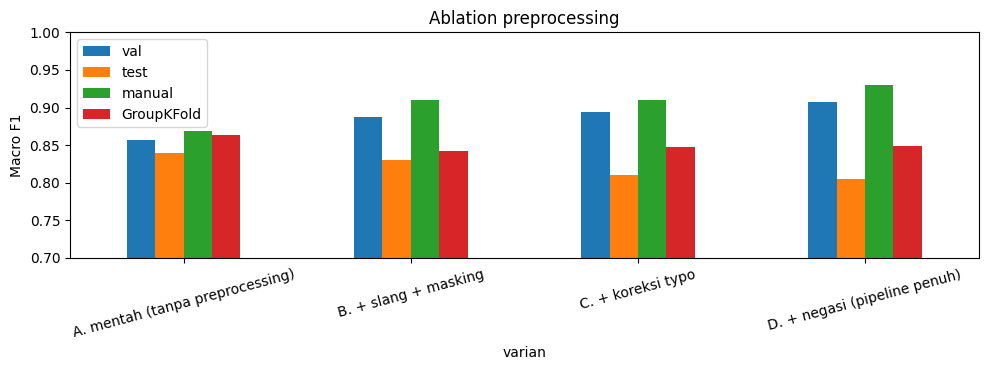

In [6]:
ax = abl[["val", "test", "manual", "GroupKFold"]].plot.bar(figsize=(10, 3.8), rot=15, ylim=(0.7, 1.0))
ax.set_ylabel("Macro F1"); ax.set_title("Ablation preprocessing"); plt.tight_layout(); plt.show()

### Cara membaca hasil (jujur)

- Preprocessing **menaikkan** skor pada pesan bergaya manusia (`val` dan `manual`), yaitu pesan yang berisi singkatan, slang, dan typo.
- Pada `test` sintetis (template yang belum pernah dilihat) dan pada **validasi silang per template**, preprocessing **tidak membantu, bahkan sedikit menurunkan** skor rata-rata (selisihnya masih di dalam simpangan baku).
- Jadi preprocessing bermanfaat untuk pesan informal, tetapi tidak boleh diklaim "selalu meningkatkan akurasi". Pipeline penuh tetap dipakai karena pesan customer nyata lebih mirip pesan informal daripada template generator, dan karena langkahnya wajib didokumentasikan dan diuji.

**Pertanyaan yang mungkin ditanyakan:** *"Kenapa pakai penanda negasi?"* → karena kata `bordir` muncul di kelas Custom *dan* di pesan yang menolak bordir; tanpa penanda negasi, model tidak bisa membedakan niatnya.

➡️ Lanjut ke `03_model.ipynb`.